In [27]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# Standard DSP configuration
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 3.1 — Convolution from the Definition
We will define our own linear convolution algorithm using a nested loop and verify it against NumPy's built-in `np.convolve`.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

# Configure figure sizes as instructed
plt.rcParams["figure.figsize"] = (9, 3.5)

def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

# Verification with Pre-Lab Question (a)
x_test = np.array([1, -1, 2])
h_test = np.array([2, 1, 0, 1])

y_custom = conv(x_test, h_test)
y_numpy = np.convolve(x_test, h_test)

print("Custom Convolution: ", y_custom)
print("NumPy Convolution:  ", y_numpy)
print("Correct match:", np.allclose(y_custom, y_numpy))

Custom Convolution:  [ 2. -1.  3.  3. -1.  2.]
NumPy Convolution:   [ 2 -1  3  3 -1  2]
Correct match: True


## Task 3.2 — Timing Comparison

In [21]:
# Measure performance with larger arrays
rng = np.random.default_rng(42)
x_large = rng.standard_normal(2000)
h_large = rng.standard_normal(1000)

t_start = time.perf_counter()
y_cust = conv(x_large, h_large)
t_custom = time.perf_counter() - t_start

t_start = time.perf_counter()
y_num = np.convolve(x_large, h_large)
t_numpy = time.perf_counter() - t_start

print(f"Custom double-loop: {t_custom:.5f} seconds")
print(f"NumPy (optimized):   {t_numpy:.5f} seconds")
print(f"Speedup factor:      {t_custom / t_numpy:.1f}x")

Custom double-loop: 1.15901 seconds
NumPy (optimized):   0.00043 seconds
Speedup factor:      2696.4x


## Task 3.3 — Numerical Linearity and Time-Invariance Testing

In [22]:
def test_system(T, name):
    # Set up test sequences
    n = np.arange(100)
    rng = np.random.default_rng(42)
    x1 = rng.standard_normal(100)
    x2 = rng.standard_normal(100)
    a, b = 1.5, -2.5

    # Linearity test
    y_combined = T(a * x1 + b * x2)
    y_indiv = a * T(x1) + b * T(x2)
    linear = np.allclose(y_combined, y_indiv)

    # Time-invariance test
    delay = 10
    # Helper to apply delay
    def delay_signal(sig, d):
        return np.concatenate([np.zeros(d), sig[:-d]])

    xd = delay_signal(x1, delay)
    yd = delay_signal(T(x1), delay)
    tinv = np.allclose(T(xd), yd)

    print(f"{name:15s} linear={linear:<6} time-invariant={tinv}")

# Define the three systems
def T1(x):  # System 1: y(n) = 3*x(n) - 2
    return 3 * x - 2

def T2(x):  # System 2: y(n) = n*x(n)
    n = np.arange(len(x))
    return n * x

def T3(x):  # System 3: y(n) = x(n) - x(n-1) (with assumed causal boundary)
    y = np.zeros_like(x)
    y[0] = x[0]
    y[1:] = x[1:] - x[:-1]
    return y

test_system(T1, "System 1 (3x-2)")
test_system(T2, "System 2 (n*x)")
test_system(T3, "System 3 (diff)")

System 1 (3x-2) linear=0      time-invariant=False
System 2 (n*x)  linear=1      time-invariant=False
System 3 (diff) linear=1      time-invariant=True


## Task 3.4 — Finding a Hidden Delay with Cross-Correlation

Estimated delay (noise=0.5): 37 samples


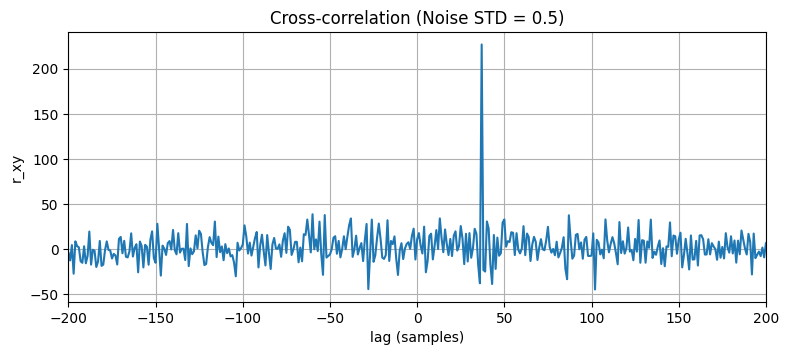

Estimated delay with noise std=1.0: 37 samples (True: 37)
Estimated delay with noise std=2.0: 37 samples (True: 37)
Estimated delay with noise std=4.0: 87 samples (True: 37)


In [23]:
def run_delay_estimation(noise_std):
    rng = np.random.default_rng(1)
    fs = 1000
    x = rng.standard_normal(500)                  # transmitted signal
    true_delay = 37
    y = np.concatenate([np.zeros(true_delay), 0.6*x])[:500] + noise_std*rng.standard_normal(500)
    r = signal.correlate(y, x, mode="full")
    lags = signal.correlation_lags(len(y), len(x), mode="full")
    est_delay = lags[np.argmax(r)]
    return lags, r, est_delay

# Plot cross-correlation at noise = 0.5
lags, r, est_delay = run_delay_estimation(0.5)
print("Estimated delay (noise=0.5):", est_delay, "samples")
plt.plot(lags, r)
plt.xlim(-200, 200)
plt.title("Cross-correlation (Noise STD = 0.5)")
plt.xlabel("lag (samples)")
plt.ylabel("r_xy")
plt.grid(True)
plt.show()

# Test with higher noise levels
for noise in [1.0, 2.0, 4.0]:
    _, _, est = run_delay_estimation(noise)
    print(f"Estimated delay with noise std={noise}: {est} samples (True: 37)")

### Distance calculation:
Given that a sound pulse travels at $343 \text{ m/s}$ and the sampling frequency is $f_s = 1000 \text{ Hz}$:
- Delay in seconds: $\tau = \frac{37 \text{ samples}}{1000 \text{ Hz}} = 0.037 \text{ s}$
- Distance: $d = v \times \tau = 343 \times 0.037 = 12.691 \text{ meters}$

## Task 3.5 — Difference Equation
Given the system: $y(n) - \frac{3}{4}y(n-1) + \frac{1}{8}y(n-2) = x(n) + x(n-1)$

In [24]:
N_samples = 10
impulse = np.zeros(N_samples)
impulse[0] = 1.0

# 1. Compute h(n) by direct recursion (for-loop)
h_rec = np.zeros(N_samples)
x_imp = impulse
for n in range(N_samples):
    val = x_imp[n] + (x_imp[n-1] if n-1 >= 0 else 0)
    if n - 1 >= 0:
        val += 0.75 * h_rec[n-1]
    if n - 2 >= 0:
        val -= 0.125 * h_rec[n-2]
    h_rec[n] = val

# 2. Compute h(n) with scipy.signal.lfilter
b = [1, 1]
a = [1, -0.75, 0.125]
h_lfilter = signal.lfilter(b, a, impulse)

# 3. Compare with analytical closed form
n = np.arange(N_samples)
h_closed = 6 * (0.5)**n - 5 * (0.25)**n

# Verification output
print(f"{'n':<3} | {'Recursion':<12} | {'lfilter':<12} | {'Closed Form':<12}")
print("-" * 48)
for i in range(N_samples):
    print(f"{i:<3} | {h_rec[i]:<12.6f} | {h_lfilter[i]:<12.6f} | {h_closed[i]:<12.6f}")

print("Matching values:", np.allclose(h_rec, h_lfilter) and np.allclose(h_lfilter, h_closed))

n   | Recursion    | lfilter      | Closed Form 
------------------------------------------------
0   | 1.000000     | 1.000000     | 1.000000    
1   | 1.750000     | 1.750000     | 1.750000    
2   | 1.187500     | 1.187500     | 1.187500    
3   | 0.671875     | 0.671875     | 0.671875    
4   | 0.355469     | 0.355469     | 0.355469    
5   | 0.182617     | 0.182617     | 0.182617    
6   | 0.092529     | 0.092529     | 0.092529    
7   | 0.046570     | 0.046570     | 0.046570    
8   | 0.023361     | 0.023361     | 0.023361    
9   | 0.011700     | 0.011700     | 0.011700    
Matching values: True


In [25]:
# 4. Compute the step response with lfilter and find its final value
step_input = np.ones(100) # Length 100 to observe steady state convergence
step_response = signal.lfilter(b, a, step_input)

# Theoretical steady state: H(1) = sum(b) / sum(a)
H_1 = sum(b) / sum(a)

print("Steady-state final response value:", step_response[-1])
print("Theoretical value H(1) = sum(b)/sum(a) =", H_1)

Steady-state final response value: 5.333333333333333
Theoretical value H(1) = sum(b)/sum(a) = 5.333333333333333


## Analysis Questions

### 1. Why is `np.convolve` so much faster than your double loop? What is the number of multiplications for lengths $L$ and $M$?
- `np.convolve` is implemented in highly optimized C-code rather than interpreted Python loops, utilizing optimized array accesses. For extremely large signals, NumPy also switches to FFT-based convolution (`scipy.signal.fftconvolve`) reducing complexity from $\mathcal{O}(LM)$ to $\mathcal{O}(N \log N)$.
- The direct definition of convolution requires exactly $L \times M$ multiplications.

### 2. Which of the three systems in Task 3.3 are LTI? Could you have predicted this without running code?
- Only **System 3** is LTI (Linear and Time-Invariant).
- **System 1** is non-linear due to the constant offset $-2$ (it does not satisfy scaling since $\mathcal{T}[0] = -2 \neq 0$).
- **System 2** is time-varying because of the multiplication factor $n$ which directly depends on absolute time.

### 3. Give two engineering applications of cross-correlation in Tanzania.
- **Locating leaks in water pipes:** Correlating acoustic noise sensors placed at two different points along water supply lines (such as DAWASA pipelines) to pinpoint the source and location of a leak.
- **Radar and GPS systems:** Estimating distance and location delays of signals transmitted to/from Tanzania Civil Aviation Authority (TCAA) airport radar towers.

### 4. Is the system in Task 3.5 FIR or IIR? Stable? Justify from the impulse response.
- The system is **IIR (Infinite Impulse Response)** because it has feedback coefficients ($a \neq [1, 0, 0]$) which make the impulse response decay infinitely.
- The system is **stable** because the impulse response decays exponentially to $0$ as $n \to \infty$ (specifically, $\lim_{n \to \infty} h(n) = 0$), meaning the poles are inside the unit circle ($|p_1| = 0.5 < 1$ and $|p_2| = 0.25 < 1$).

In [26]:
## Lab Tasks and Verified Results